# Boston house-prices: Random Forest regression

Predict the median house value (`MEDV`, in **$1000s**) of Boston neighbourhoods with a Random Forest regressor, evaluate it with five regression metrics, and study the effect of the number of trees.

> `sklearn.datasets.load_boston` was removed in Scikit-Learn 1.2, so the data is read from the CSV copy shipped with Scikit-Learn 1.1 (`boston_house_prices.csv`, saved next to this notebook). It is the same dataset as on Kaggle.

## A · Load the dataset and split it (`random_state=42`)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

# Same file as sklearn 1.1's load_boston(); the first line is a header with the shape, so skip it.
df = pd.read_csv('boston_house_prices.csv', skiprows=1)
print(df.shape, '| missing values:', int(df.isna().sum().sum()))
display(df.head())

X = df.drop(columns='MEDV')
y = df['MEDV']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('train:', X_train.shape, ' test:', X_test.shape)

(506, 14) | missing values: 0


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


train: (404, 13)  test: (102, 13)


## B · Train a Random Forest with `n_estimators=100`

In [2]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

## C · Evaluate (test set)

- **MSE** = mean((y − ŷ)²)  
- **RMSE** = √MSE (same unit as the target)  
- **MAE** = mean(|y − ŷ|)  
- **MAPE** = mean(|y − ŷ| / |y|) × 100  
- **R²** = 1 − SS_res / SS_tot

In [3]:
def regression_metrics(y_true, y_hat):
    mse = mean_squared_error(y_true, y_hat)
    return {'MSE': mse,
            'RMSE': np.sqrt(mse),
            'MAE': mean_absolute_error(y_true, y_hat),
            'MAPE (%)': mean_absolute_percentage_error(y_true, y_hat) * 100,
            'R²': r2_score(y_true, y_hat)}

test_metrics = regression_metrics(y_test, y_pred)
train_metrics = regression_metrics(y_train, rf.predict(X_train))
pd.DataFrame({'Train': train_metrics, 'Test': test_metrics}).round(4)

,Train,Test
MSE,1.9664,7.8802
RMSE,1.4023,2.8072
MAE,0.8986,2.0367
MAPE (%),4.5097,11.0866
R²,0.9774,0.8925


The model fits the training rows much more closely than the test rows (typical for a forest that memorises bootstrap samples), so **only the Test column** should be used to judge generalisation.

## D · Ground truth vs. predictions

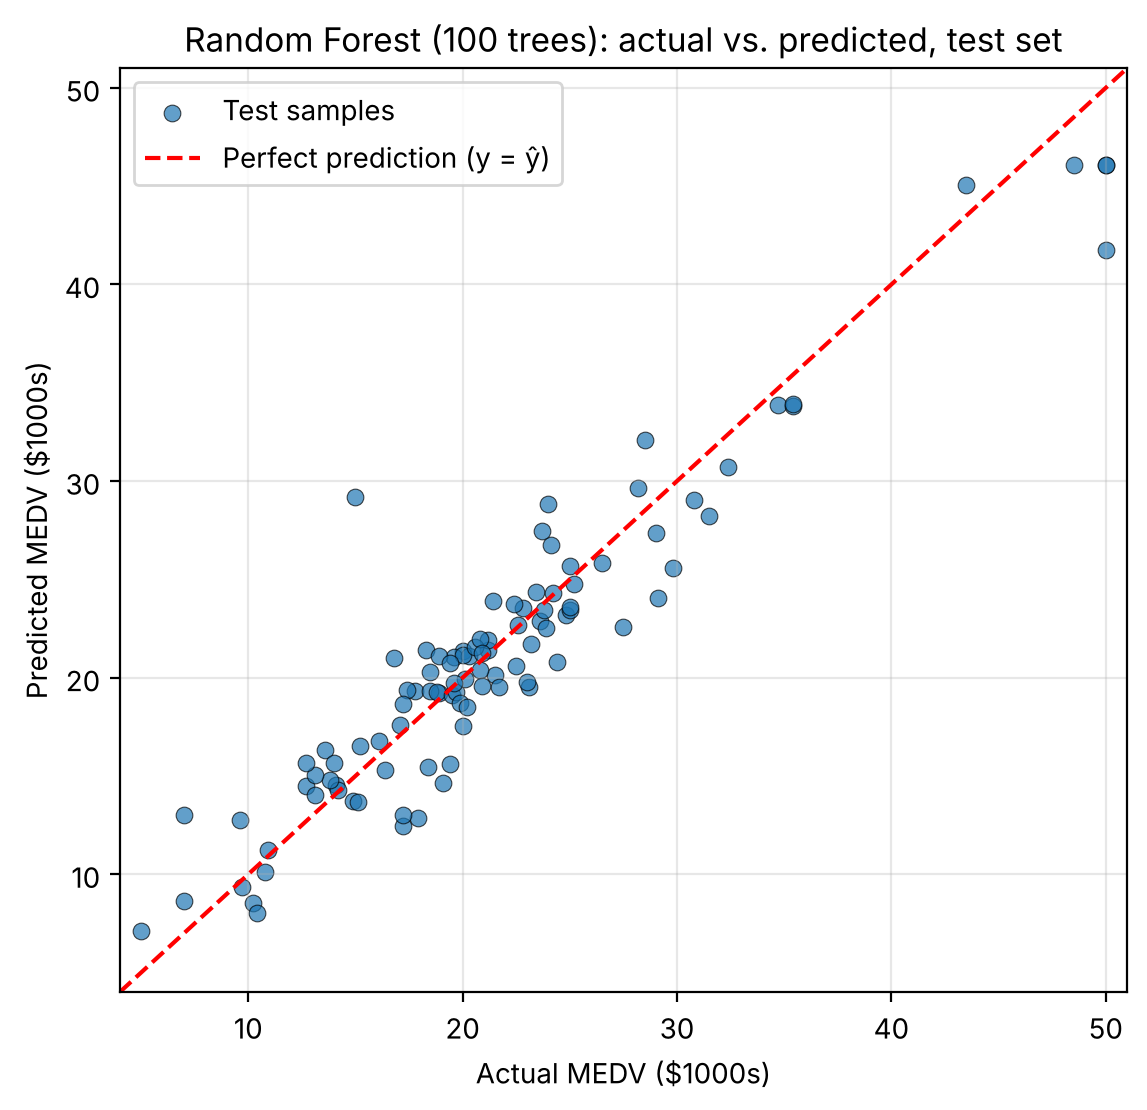

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y_test, y_pred, alpha=0.7, edgecolor='k', linewidth=0.4, label='Test samples')
lims = [min(y_test.min(), y_pred.min()) - 1, max(y_test.max(), y_pred.max()) + 1]
ax.plot(lims, lims, 'r--', label='Perfect prediction (y = ŷ)')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('Actual MEDV ($1000s)'); ax.set_ylabel('Predicted MEDV ($1000s)')
ax.set_title('Random Forest (100 trees): actual vs. predicted, test set')
ax.legend(); ax.grid(alpha=0.3); plt.show()

Most points lie close to the diagonal. The largest misses are a few isolated houses: one is over-predicted by about \$14k (actual \$15k, predicted \$29k) and the capped \$50k house is under-predicted by about \$8k, because a forest averages leaf values and cannot extrapolate to the dataset's ceiling.

## E · Compare `n_estimators` = 50, 100, 200

In [5]:
rows = []
models = {}
for n in [50, 100, 200]:
    m = RandomForestRegressor(n_estimators=n, random_state=42).fit(X_train, y_train)
    models[n] = m
    p = m.predict(X_test)
    rows.append({'Number of trees': n,
                 'Test RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'Test R²': r2_score(y_test, p)})
results = pd.DataFrame(rows)
results.round(4)

,Number of trees,Test RMSE,Test R²
0,50,2.7480,0.8970
1,100,2.8072,0.8925
2,200,2.9316,0.8828


## F · RMSE in dollars

`MEDV` is expressed in thousands of dollars, so RMSE in dollars = RMSE × 1000.

,Number of trees,Test RMSE,Test R²,Test RMSE ($)
0,50,2.7480,0.8970,2747.9594
1,100,2.8072,0.8925,2807.1725
2,200,2.9316,0.8828,2931.5591


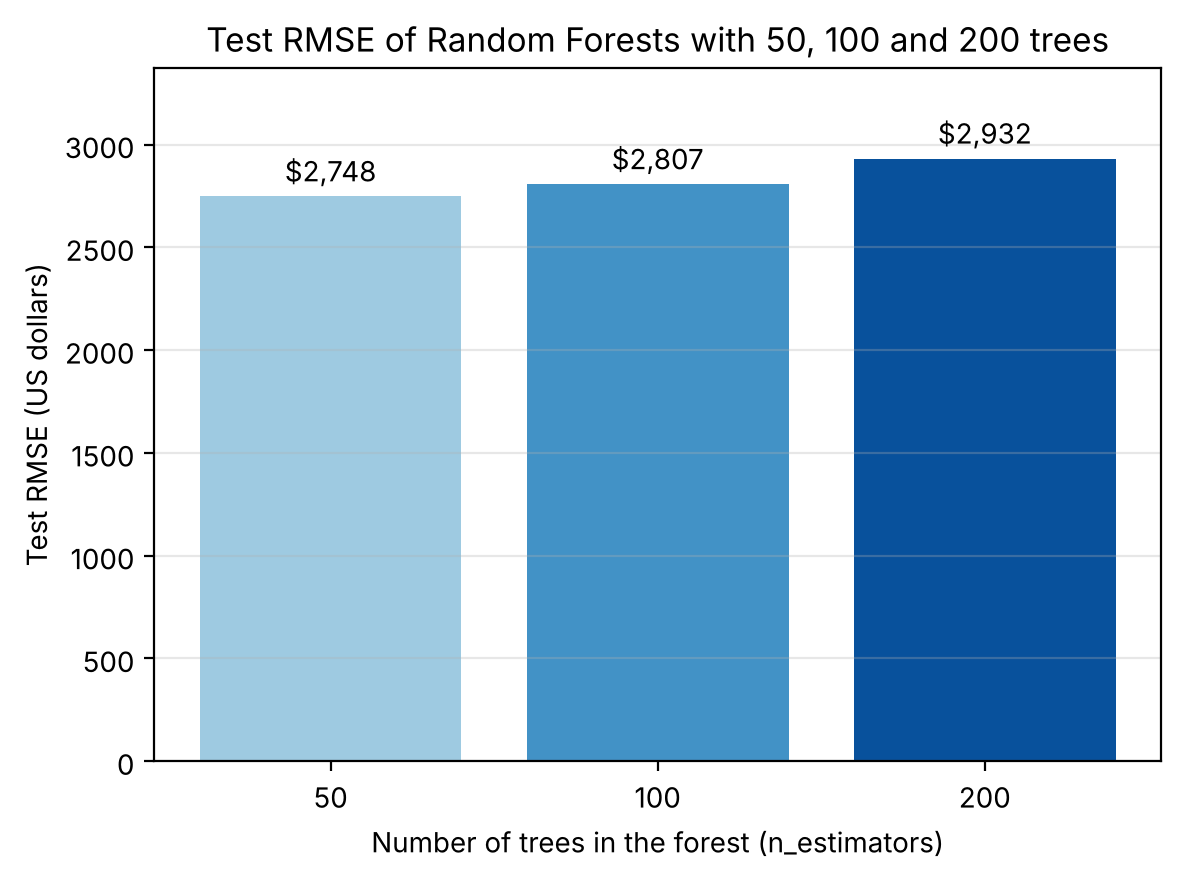

In [6]:
results['Test RMSE ($)'] = results['Test RMSE'] * 1000
display(results.round(4))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
bars = ax.bar(results['Number of trees'].astype(str), results['Test RMSE ($)'], color=['#9ecae1', '#4292c6', '#08519c'])
ax.bar_label(bars, labels=[f'${v:,.0f}' for v in results['Test RMSE ($)']], padding=3)
ax.set_xlabel('Number of trees in the forest (n_estimators)')
ax.set_ylabel('Test RMSE (US dollars)')
ax.set_title('Test RMSE of Random Forests with 50, 100 and 200 trees')
ax.set_ylim(0, results['Test RMSE ($)'].max() * 1.15); ax.grid(axis='y', alpha=0.3)
plt.show()

**Interpretation:** more trees did **not** improve the test error here: RMSE is lowest with 50 trees (≈ \$2,748), then \$2,807 with 100 and \$2,932 with 200, and R² moves from 0.897 to 0.883. These gaps are small and, on a 102-row test set, are mostly noise from which houses happen to be hit by the few large errors, not evidence that fewer trees are better. In general more trees reduce variance and the curve flattens quickly, so beyond ~50–100 trees extra cost buys almost nothing. A typical error of about \$2.7–2.9k compares with a mean house value of about \$22.5k.